# Detección de Fraude Financiero con Machine Learning
## Notebook 02 · Preparación de los datos
**Proyecto Final – Minería de Datos · Metodología CRISP-DM (fase 3)**

Se aplican las decisiones tomadas en la Fase 2 (notebook 01):

| Paso | Acción | Motivo |
|---|---|---|
| 3.1 | Eliminar duplicados exactos | Evitar que una transacción quede en entrenamiento y en prueba |
| 3.2 | *Feature engineering*: `Amount_log`, `Hour_sin`, `Hour_cos` | Reducir asimetría del monto y capturar el patrón horario |
| 3.3 | División estratificada 60 / 20 / 20 | Conservar la proporción de fraude en cada conjunto |
| 3.4 | Escalado ajustado solo con entrenamiento | Evitar fuga de información |
| 3.5 | SMOTE solo sobre entrenamiento, dentro de un `imblearn.Pipeline` | Balancear sin contaminar validación ni prueba |
| 3.6 | Experimento: SMOTE aplicado incorrectamente | Mostrar con números por qué importa el orden |
| 3.7 | Guardar conjuntos y preprocesador | Reutilizarlos en el modelado y en la app |

Toda la lógica está en `src/data_preprocessing.py`; este notebook la ejecuta paso a paso y muestra los resultados.

In [1]:
import sys
from pathlib import Path

# Permite importar src/ tanto si el kernel arranca en notebooks/ como en la raíz del proyecto
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

from src.config import (
    FIG_DIR, RANDOM_STATE, COLUMNAS_CRUDAS, FEATURES, TARGET,
    COLOR_LEGITIMA, COLOR_FRAUDE, COLOR_SINTETICO, NOMBRES_CLASES, fijar_semillas,
)
from src.data_preprocessing import (
    cargar_datos, limpiar_datos, crear_variables, dividir_datos, separar_xy,
    construir_preprocesador, crear_smote, pipeline_con_balanceo,
    resumen_splits, guardar_artefactos_preparacion,
)

fijar_semillas()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.35,
    "grid.linewidth": 0.6,
})

def guardar_figura(nombre):
    """Guarda la figura actual en reports/figures para el artículo IEEE."""
    plt.savefig(FIG_DIR / nombre, bbox_inches="tight", dpi=150)

---
## 3.1 Limpieza
El dataset no tiene valores nulos (Fase 2), así que la limpieza consiste en eliminar duplicados exactos. Se conserva el número de fila original como `id_transaccion` para poder rastrear cada transacción en el dashboard.

In [2]:
df_crudo = cargar_datos()
df, info_limpieza = limpiar_datos(df_crudo)

for clave, valor in info_limpieza.items():
    print(f"{clave:<32} {valor:>10,}")

filas_originales                    284,807
duplicados_eliminados                 1,081
fraudes_duplicados_eliminados            19
filas_finales                       283,726
fraudes_finales                         473
nulos                                     0


---
## 3.2 *Feature engineering*

| Variable nueva | Fórmula | Reemplaza a | Motivo |
|---|---|---|---|
| `Amount_log` | $\log(1 + \text{Amount})$ | `Amount` | La asimetría baja de 16,98 a 0,16 |
| `Hour_sin` | $\sin(2\pi \cdot h / 24)$ | `Time` | La tasa de fraude se multiplica por 10 de madrugada |
| `Hour_cos` | $\cos(2\pi \cdot h / 24)$ | `Time` | Junto con el seno, la hora 23 queda "cerca" de la hora 0 |

donde $h$ = hora del día derivada de `Time`. `Time` crudo no se usa como variable porque es un contador de 0 a 172 792 s: en producción tomaría valores que el modelo nunca vio.

In [3]:
df = crear_variables(df)
print(f"Variables del modelo ({len(FEATURES)}):", FEATURES)

# Comprobación: cada hora queda en un punto distinto del círculo y 23 h queda junto a 0 h
horas = pd.DataFrame({"Hora": range(24)})
horas["Hour_sin"] = np.sin(2 * np.pi * horas["Hora"] / 24)
horas["Hour_cos"] = np.cos(2 * np.pi * horas["Hora"] / 24)
distancia = lambda a, b: np.hypot(*(horas.loc[a, ["Hour_sin", "Hour_cos"]] - horas.loc[b, ["Hour_sin", "Hour_cos"]]))
print(f"Distancia cíclica 23 h – 0 h: {distancia(23, 0):.3f} | 0 h – 12 h: {distancia(0, 12):.3f}")
print(f"Asimetría: Amount = {df['Amount'].skew():.2f} | Amount_log = {df['Amount_log'].skew():.2f}")

df[["Time", "Amount", "Amount_log", "Hour_sin", "Hour_cos", TARGET]].head()

Variables del modelo (31): ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount_log', 'Hour_sin', 'Hour_cos']
Distancia cíclica 23 h – 0 h: 0.261 | 0 h – 12 h: 2.000
Asimetría: Amount = 16.98 | Amount_log = 0.16


,Time,Amount,Amount_log,Hour_sin,Hour_cos,Class
id_transaccion,,,,,,
0,0.0,149.62,5.014760,0.0,1.0,0
1,0.0,2.69,1.305626,0.0,1.0,0
2,1.0,378.66,5.939276,0.0,1.0,0
3,1.0,123.50,4.824306,0.0,1.0,0
4,2.0,69.99,4.262539,0.0,1.0,0


---
## 3.3 División estratificada
- **Entrenamiento (60 %)**: ajustar escaladores, SMOTE y modelos.
- **Validación (20 %)**: *early stopping* y elección del umbral de decisión.
- **Prueba (20 %)**: solo para la evaluación final, con la proporción real de fraude.

La estratificación garantiza que los tres conjuntos tengan la misma proporción de fraude. Sin ella, con tan pocos fraudes, un conjunto podría quedar con muchos menos casos que otro.

In [4]:
splits = dividir_datos(df)
display(resumen_splits(splits))

# Verificaciones de fuga: ningún id ni ninguna transacción idéntica en dos conjuntos
ids = {n: set(d.index) for n, d in splits.items()}
print("Ids compartidos train–val:", len(ids["train"] & ids["val"]),
      "| train–test:", len(ids["train"] & ids["test"]),
      "| val–test:", len(ids["val"] & ids["test"]))
union = pd.concat([d[COLUMNAS_CRUDAS] for d in splits.values()])
print("Transacciones idénticas repartidas entre conjuntos:", int(union.duplicated().sum()))

X_train, y_train = separar_xy(splits["train"])
X_val, y_val = separar_xy(splits["val"])
X_test, y_test = separar_xy(splits["test"])

,Filas,Fraudes,% fraude
train,170235,284,0.1668
val,56745,94,0.1657
test,56746,95,0.1674


Ids compartidos train–val: 0 | train–test: 0 | val–test: 0


Transacciones idénticas repartidas entre conjuntos: 0


---
## 3.4 Escalado

| Variables | Escalador | Motivo |
|---|---|---|
| `V1`–`V28` | `StandardScaler` | Ya están centradas pero con varianzas distintas; igualarlas ayuda a las redes neuronales |
| `Amount_log` | `RobustScaler` | Usa mediana e IQR, así los montos extremos no deforman la escala |
| `Hour_sin`, `Hour_cos` | Ninguno | Ya están en $[-1, 1]$ |

El preprocesador se ajusta **solo con entrenamiento** y luego se aplica a validación y prueba. Si se ajustara con todos los datos, la media y la desviación de prueba influirían en el entrenamiento.

,Desv. V1 antes,Desv. V1 después,Desv. V28 antes,Desv. V28 después,Mediana Amount_log después
Entrenamiento,1.952,1.000,0.333,1.000,0.000
Validación,1.934,0.991,0.303,0.909,0.004


Validación queda cerca de media 0 / desviación 1 sin haber participado en el ajuste.


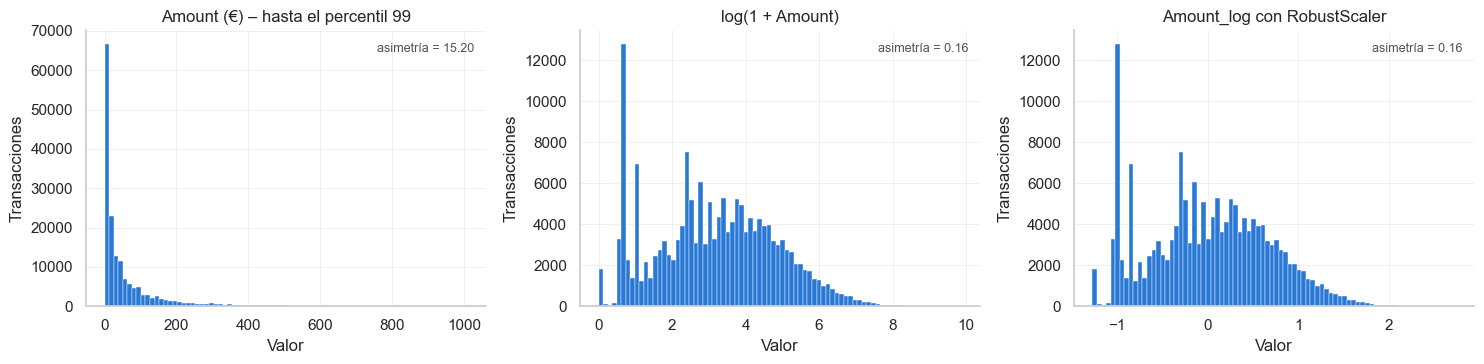

In [5]:
preprocesador = construir_preprocesador().fit(X_train)

X_train_s = preprocesador.transform(X_train)
X_val_s = preprocesador.transform(X_val)
X_test_s = preprocesador.transform(X_test)

comparacion = pd.DataFrame({
    "Desv. V1 antes": [X_train["V1"].std(), X_val["V1"].std()],
    "Desv. V1 después": [X_train_s["V1"].std(), X_val_s["V1"].std()],
    "Desv. V28 antes": [X_train["V28"].std(), X_val["V28"].std()],
    "Desv. V28 después": [X_train_s["V28"].std(), X_val_s["V28"].std()],
    "Mediana Amount_log después": [X_train_s["Amount_log"].median(), X_val_s["Amount_log"].median()],
}, index=["Entrenamiento", "Validación"])
display(comparacion.round(3))
print("Validación queda cerca de media 0 / desviación 1 sin haber participado en el ajuste.")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
monto = splits["train"]["Amount"]
etiquetas = [("Amount (€) – hasta el percentil 99", monto, monto[monto <= monto.quantile(0.99)]),
             ("log(1 + Amount)", X_train["Amount_log"], X_train["Amount_log"]),
             ("Amount_log con RobustScaler", X_train_s["Amount_log"], X_train_s["Amount_log"])]
for ax, (titulo, serie, visible) in zip(axes, etiquetas):
    ax.hist(visible, bins=80, color=COLOR_LEGITIMA, edgecolor="white", linewidth=0.3)
    ax.set(title=titulo, xlabel="Valor", ylabel="Transacciones")
    # La asimetría se calcula con todos los datos, no solo con el tramo visible
    ax.text(0.97, 0.92, f"asimetría = {serie.skew():.2f}", transform=ax.transAxes,
            ha="right", fontsize=9, color="#52514e")
plt.tight_layout()
guardar_figura("09_transformacion_amount.png")
plt.show()

---
## 3.5 Balanceo de clases con SMOTE
**SMOTE** (*Synthetic Minority Over-sampling Technique*) crea fraudes sintéticos: toma un fraude real, elige uno de sus $k = 5$ vecinos fraudulentos más cercanos y genera un punto nuevo en el segmento que los une.

El parámetro `sampling_strategy` fija la proporción fraudes / legítimas tras el balanceo. No se busca necesariamente 50/50: con solo 284 fraudes reales, un balanceo total crearía casi 170 000 fraudes sintéticos a partir de muy pocos ejemplos, con riesgo de sobreajuste. La proporción óptima se elegirá con validación cruzada en la Fase 4.

In [6]:
filas = []
for estrategia in (0.01, 0.1, 0.25, 0.5, 1.0):
    _, y_bal = crear_smote(estrategia).fit_resample(X_train_s, y_train)
    reales = int(y_train.sum())
    filas.append({
        "sampling_strategy": estrategia,
        "Legítimas": int((y_bal == 0).sum()),
        "Fraudes reales": reales,
        "Fraudes sintéticos": int(y_bal.sum()) - reales,
        "% fraude tras SMOTE": round(y_bal.mean() * 100, 2),
        "Sintéticos por fraude real": round((int(y_bal.sum()) - reales) / reales, 1),
    })
estrategias = pd.DataFrame(filas).set_index("sampling_strategy")
display(estrategias)
print(f"Sin SMOTE, el entrenamiento tiene {y_train.mean():.4%} de fraudes.")

,Legítimas,Fraudes reales,Fraudes sintéticos,% fraude tras SMOTE,Sintéticos por fraude real
sampling_strategy,,,,,
0.01,169951,284,1415,0.99,5.0
0.10,169951,284,16711,9.09,58.8
0.25,169951,284,42203,20.00,148.6
0.50,169951,284,84691,33.33,298.2
1.00,169951,284,169667,50.00,597.4


Sin SMOTE, el entrenamiento tiene 0.1668% de fraudes.


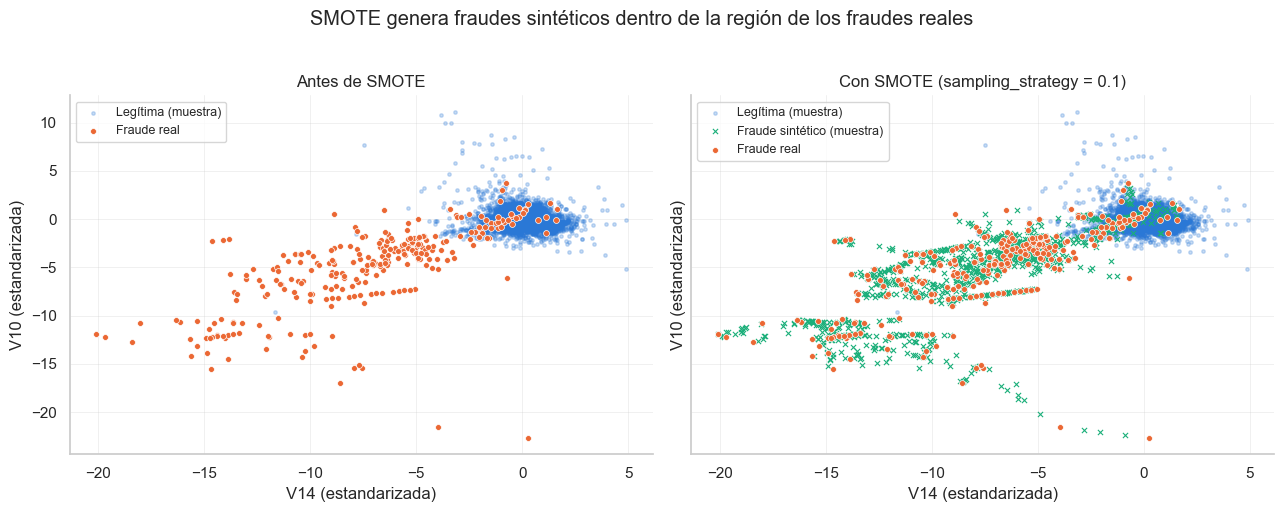

In [7]:
# Visualización de los fraudes sintéticos en el plano de las dos variables más separables (V14, V10)
X_sm, y_sm = crear_smote(0.1).fit_resample(X_train_s, y_train)
n_original = len(X_train_s)
# imblearn agrega las filas sintéticas al final del conjunto original
es_sintetico = np.r_[np.zeros(n_original, dtype=bool), np.ones(len(X_sm) - n_original, dtype=bool)]

legit = X_train_s[y_train.values == 0].sample(6000, random_state=RANDOM_STATE)
fraude_real = X_train_s[y_train.values == 1]
sinteticos = X_sm[es_sintetico].sample(1500, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, con_smote in zip(axes, (False, True)):
    ax.scatter(legit["V14"], legit["V10"], s=6, alpha=0.25, color=COLOR_LEGITIMA,
               label="Legítima (muestra)", rasterized=True)
    if con_smote:
        ax.scatter(sinteticos["V14"], sinteticos["V10"], s=14, marker="x", linewidths=0.8,
                   color=COLOR_SINTETICO, label="Fraude sintético (muestra)")
    ax.scatter(fraude_real["V14"], fraude_real["V10"], s=18, color=COLOR_FRAUDE,
               edgecolor="white", linewidth=0.5, label="Fraude real")
    ax.set(xlabel="V14 (estandarizada)", ylabel="V10 (estandarizada)",
           title="Con SMOTE (sampling_strategy = 0.1)" if con_smote else "Antes de SMOTE")
    ax.legend(loc="upper left", fontsize=9)
fig.suptitle("SMOTE genera fraudes sintéticos dentro de la región de los fraudes reales", y=1.02)
plt.tight_layout()
guardar_figura("10_smote_proyeccion.png")
plt.show()

### SMOTE dentro de un `imblearn.Pipeline`
En la Fase 4 los modelos se entrenan con validación cruzada estratificada. Si SMOTE se aplicara una sola vez antes de la validación cruzada, los fraudes sintéticos generados a partir de un pliegue de validación aparecerían en los pliegues de entrenamiento. La solución es poner el escalador y SMOTE **dentro** del pipeline: `imblearn.Pipeline` ejecuta SMOTE solo en `fit()` (los pliegues de entrenamiento) y lo omite en `predict()`.

`pipeline_con_balanceo(modelo, sampling_strategy)` construye esa cadena. Con `sampling_strategy=None` se omite SMOTE, para comparar con `class_weight` / `scale_pos_weight`.

In [8]:
for estrategia in (0.1, None):
    ejemplo = pipeline_con_balanceo(XGBClassifier(), sampling_strategy=estrategia)
    pasos = " -> ".join(f"{nombre} ({type(paso).__name__})" for nombre, paso in ejemplo.steps)
    print(f"sampling_strategy={estrategia}:  {pasos}")

sampling_strategy=0.1:  prep (ColumnTransformer) -> smote (SMOTE) -> modelo (XGBClassifier)
sampling_strategy=None:  prep (ColumnTransformer) -> modelo (XGBClassifier)


---
## 3.6 Experimento: ¿qué pasa si SMOTE se aplica antes de dividir?
Se entrena el mismo XGBoost de dos formas:

- **Correcta:** escalado y SMOTE dentro del pipeline, solo con entrenamiento. Se evalúa en prueba con la proporción real.
- **Con fuga:** SMOTE aplicado a todo el dataset y luego dividido. El conjunto de prueba contiene fraudes sintéticos "parientes" de fraudes de entrenamiento.

Ambos usan `sampling_strategy = 0.5`, umbral 0,5 y los mismos hiperparámetros.

In [9]:
def xgb_experimento():
    return XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8,
                         colsample_bytree=0.8, tree_method="hist", n_jobs=-1,
                         random_state=RANDOM_STATE)

def metricas(y_true, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    return {"Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, prob), "PR-AUC": average_precision_score(y_true, prob)}

# --- Forma correcta: train (60 %) + val (20 %) para entrenar, prueba intacta (20 %) ---
X_trval = pd.concat([X_train, X_val]); y_trval = pd.concat([y_train, y_val])
correcto = pipeline_con_balanceo(xgb_experimento(), sampling_strategy=0.5).fit(X_trval, y_trval)
res_correcto = metricas(y_test, correcto.predict_proba(X_test)[:, 1])
res_correcto["Fraudes en prueba"] = int(y_test.sum())

# --- Forma con fuga: SMOTE sobre TODO el dataset y luego división 80/20 ---
X_todo, y_todo = separar_xy(df)
X_todo_s = construir_preprocesador().fit_transform(X_todo)
X_fuga, y_fuga = crear_smote(0.5).fit_resample(X_todo_s, y_todo)
Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(X_fuga, y_fuga, test_size=0.20, stratify=y_fuga,
                                              random_state=RANDOM_STATE)
con_fuga = xgb_experimento().fit(Xf_tr, yf_tr)
res_fuga = metricas(yf_te, con_fuga.predict_proba(Xf_te)[:, 1])
res_fuga["Fraudes en prueba"] = int(yf_te.sum())

experimento = pd.DataFrame({"Correcto (SMOTE solo en train)": res_correcto,
                            "Con fuga (SMOTE antes de dividir)": res_fuga}).T
display(experimento.round(4))
print(f"Proporción de fraude en la prueba 'con fuga': {yf_te.mean():.1%} (la real es {y_test.mean():.3%})")

,Precision,Recall,F1,ROC-AUC,PR-AUC,Fraudes en prueba
Correcto (SMOTE solo en train),0.8795,0.7684,0.8202,0.9739,0.8149,95.0
Con fuga (SMOTE antes de dividir),0.9998,0.9999,0.9998,1.0000,1.0000,28325.0


Proporción de fraude en la prueba 'con fuga': 33.3% (la real es 0.167%)


**Lectura del experimento.** Con fuga, las métricas parecen casi perfectas, pero es un espejismo: la prueba contiene un tercio de fraudes (en la realidad son el 0,17 %), y la mayoría son sintéticos interpolados a partir de fraudes que el modelo ya vio en entrenamiento. Las métricas de la forma correcta son las que se pueden esperar en producción.

---
## 3.7 Guardado de artefactos
- `data/processed/{train,val,test}.parquet`: conjuntos **sin escalar** con todas las columnas (incluye `Amount` y `Time`, necesarios para el análisis de costo y el monitoreo en tiempo real).
- `models/preprocesador.joblib`: escalador ajustado con entrenamiento, para la DNN, el autoencoder y la app.
- `data/processed/metadata_preparacion.json`: resumen reproducible de la preparación.

In [10]:
metadata = guardar_artefactos_preparacion(splits, preprocesador, info_limpieza)
print("Guardado:", metadata["fecha"])
for ruta in sorted((RAIZ / "data" / "processed").glob("*")) + [RAIZ / metadata["preprocesador"]]:
    if ruta.name != ".gitkeep":
        print(f"  {ruta.relative_to(RAIZ)}  ({ruta.stat().st_size / 1e6:.1f} MB)")

Guardado: 2026-11-07T11:41:04
  data\processed\metadata_preparacion.json  (0.0 MB)
  data\processed\test.parquet  (16.9 MB)
  data\processed\train.parquet  (49.2 MB)
  data\processed\val.parquet  (17.0 MB)
  models\preprocesador.joblib  (0.0 MB)


---
# Resumen de la Fase 3

| Paso | Resultado |
|---|---|
| Limpieza | 1 081 duplicados eliminados (19 fraudes). Quedan **283 726** transacciones y **473** fraudes |
| Variables | 31 variables: `V1`–`V28`, `Amount_log`, `Hour_sin`, `Hour_cos`. La asimetría del monto baja de 16,98 a 0,16 |
| División | Entrenamiento 170 235 (284 fraudes) · Validación 56 745 (94) · Prueba 56 746 (95). Proporción de fraude ≈ 0,167 % en los tres. Ninguna transacción se repite entre conjuntos |
| Escalado | Ajustado solo con entrenamiento. Validación queda con desviación ≈ 1 sin haber participado en el ajuste |
| SMOTE | Probado con proporciones de 0,01 a 1,0. Con 0,1 se crean 16 711 fraudes sintéticos (59 por cada fraude real); con 1,0 serían 169 667 (597 por fraude real). La proporción final se elige en la Fase 4 |

**Experimento de fuga de datos.** Un mismo XGBoost obtiene PR-AUC = **0,815** y Recall = 0,768 cuando SMOTE se aplica correctamente (solo en entrenamiento), y PR-AUC = **1,000** y Recall = 1,000 cuando SMOTE se aplica antes de dividir. Las métricas "perfectas" son falsas: la prueba contaminada tiene 33,3 % de fraudes (frente al 0,167 % real) y casi todos son sintéticos derivados de fraudes que el modelo vio al entrenar. Este resultado justifica aplicar SMOTE dentro de un `imblearn.Pipeline`.

**Artefactos para la Fase 4.**
- `data/processed/train.parquet`, `val.parquet`, `test.parquet` (sin escalar, con todas las columnas).
- `models/preprocesador.joblib` (escalador ajustado con entrenamiento).
- `data/processed/metadata_preparacion.json`.
- `pipeline_con_balanceo(modelo, sampling_strategy)` en `src/data_preprocessing.py`: escalador → SMOTE (opcional) → modelo.